# 01 – Explore sources

Compare the two downloads of ring-necked parakeet (*Psittacula krameri*) records for the UK:

- **GBIF** (simple format, downloaded 10 Nov 2026)
- **NBN Atlas** (full Darwin Core, downloaded 10 Nov 2026)

Steps: load each source and keep only the useful columns, compare records per year, measure how many records appear in both, merge them into one table, and decide which records to filter out. Choices made here are logged in `decisions.md`.

This notebook is where the decisions were made. The merge and filters are reproduced in `src/build_records.py`, which saves the result to `data/processed/records.parquet`. Later notebooks start from that file, not from this notebook.

In [1]:
import sys

import pandas as pd
import matplotlib.pyplot as plt
import requests  # for looking up GBIF dataset names

sys.path.insert(0, "../src")  # shared helpers in src/
import plot_style  # colours only; font sizes are set per plot here

In [2]:
# Raw downloads (not tracked in Git, see README for how to re-download)
NBN_PATH = "../data/raw/records-2026-11-10/records-2026-11-10.csv"
GBIF_PATH = "../data/raw/0000595-261110092616502.csv"

# Load Data

## GBIF

First load all columns once to see which ones contain any information. For each column:
- `fill_pct`: percentage of rows with a value
- `n_unique`: number of different values

Columns that are empty (`n_unique == 0`) or the same in every row (`n_unique == 1`) are left out.

In [3]:
raw = pd.read_csv(GBIF_PATH, sep="\t", quoting=3, low_memory=False)

In [71]:
summary = pd.DataFrame({
    "fill_pct": raw.notna().mean().mul(100).round(1),
    "n_unique": raw.nunique(),
})
print("empty:", (summary.n_unique == 0).sum(), "| constant:", (summary.n_unique == 1).sum())
summary[summary.n_unique > 1].sort_values("fill_pct", ascending=False)

empty: 7 | constant: 10


,fill_pct,n_unique
gbifID,100.0,192792
datasetKey,100.0,60
occurrenceID,100.0,192756
lastInterpreted,100.0,189762
taxonRank,100.0,2
scientificName,100.0,3
verbatimScientificName,100.0,4
license,100.0,3
taxonKey,100.0,3
occurrenceStatus,100.0,2


In [4]:
# Columns kept for the comparison: IDs, date, location, data quality, and where the record came from
GBIF_COLS = [
    "gbifID", "datasetKey", "occurrenceID",
    "eventDate", "year", "month",
    "decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters",
    "stateProvince",
    "scientificName", "taxonRank", "occurrenceStatus", "issue",
    "institutionCode", "collectionCode", "catalogNumber", "individualCount",
]

gbif = pd.read_csv(
    GBIF_PATH,
    sep="\t",
    quoting=3,  # csv.QUOTE_NONE, recommended by GBIF for simple downloads
    usecols=GBIF_COLS,
    dtype={"gbifID": str, "occurrenceID": str, "catalogNumber": str},
)
# eventDate is kept as text: GBIF mixes full dates, year-only ("1989") and year-month ("1991-02")

In [73]:
# Check the columns with a few unexpected values
for col in ["occurrenceStatus", "scientificName", "taxonRank", "stateProvince"]:
    print(gbif[col].value_counts(dropna=False), "\n")

# GBIF data-quality flags; one record can have several, separated by ";"
gbif["issue"].str.split(";").explode().value_counts()

occurrenceStatus
DETECTED        192661
NOT_DETECTED       131
Name: count, dtype: int64 

scientificName
Psittacula krameri (Scopoli, 1769)                  192786
Psittacula krameri manillensis (Bechstein, 1800)         4
Psittacula krameri borealis (Neumann, 1915)              2
Name: count, dtype: int64 

taxonRank
SPECIES       192786
SUBSPECIES         6
Name: count, dtype: int64 

stateProvince
England                               190872
England - Greater London                 653
Wales                                    487
Scotland                                 379
NaN                                      326
Northern Ireland                          25
England - Kent                            17
England - Surrey                           9
England - West Midlands                    6
England - Greater Manchester               4
England - Hertfordshire                    4
England - East Riding of Yorkshire         3
England - Cambridgeshire                   2
England - 

issue
CONTINENT_DERIVED_FROM_COORDINATES                  191935
GEODETIC_DATUM_ASSUMED_WGS84                        160400
TAXON_CONCEPT_ID_NOT_FOUND                          160368
COORDINATE_ROUNDED                                  157203
TAXON_ID_NOT_FOUND                                    5646
RECORDED_DATE_INVALID                                  360
COUNTRY_DERIVED_FROM_COORDINATES                       158
CONTINENT_COORDINATE_MISMATCH                           31
RECORDED_DATE_MISMATCH                                  20
INDIVIDUAL_COUNT_INVALID                                14
OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COUNT         8
COUNTRY_INVALID                                          6
SCIENTIFIC_NAME_ID_NOT_FOUND                             3
Name: count, dtype: int64

In [5]:
# Remove the 131 NOT_DETECTED records (someone looked and did not find a parakeet)
gbif = gbif[gbif["occurrenceStatus"] == "DETECTED"]

## NBN Atlas

Same check as for GBIF. The NBN file has 200 columns, of which 140 are empty and 19 are the same in every row.

In [75]:
raw = pd.read_csv(NBN_PATH, low_memory=False)

In [76]:
summary = pd.DataFrame({
    "fill_pct": raw.notna().mean().mul(100).round(1),
    "n_unique": raw.nunique(),
})
print("empty:", (summary.n_unique == 0).sum(), "| constant:", (summary.n_unique == 1).sum())
summary[summary.n_unique > 1].sort_values("fill_pct", ascending=False)

empty: 140 | constant: 19


,fill_pct,n_unique
identificationVerificationStatus,100.0,3
month,100.0,12
year,100.0,61
stateProvince,100.0,5
countryCode,100.0,2
country,100.0,2
coordinateUncertaintyInMeters,100.0,49
decimalLongitude,100.0,12069
decimalLatitude,100.0,11859
occurrenceID,100.0,242678


In [6]:
# Columns kept: IDs, date, location (incl. grid reference), data quality, and where the record came from
NBN_COLS = [
    "recordID", "occurrenceID",
    "eventDate", "year", "month", "startDayOfYear", "endDayOfYear",
    "decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters",
    "gridReference", "stateProvince", "countryCode",
    "identificationVerificationStatus", "vitality",
    "datasetName", "institutionCode", "collectionCode", "individualCount"
]

nbn = pd.read_csv(
    NBN_PATH,
    usecols=NBN_COLS,
    dtype={"recordID": str, "occurrenceID": str, "gridReference": str},
    parse_dates=["eventDate"],  # empty (NaT) for the ~22% of records with only year and month
)

del raw  # full tables no longer needed

# Compare

## Records per year

These are raw record counts, not numbers of birds. Growth reflects both the spread and the rise in recording (e.g. eBird, BirdTrack). 2026 is incomplete (downloaded in November).

In [7]:
# Count records per year for each source; years missing in one source get 0
per_year = pd.DataFrame({
    "NBN Atlas": nbn["year"].value_counts(),
    "GBIF": gbif["year"].dropna().astype(int).value_counts(),  # 0.1% of GBIF records have no year
}).sort_index().fillna(0)

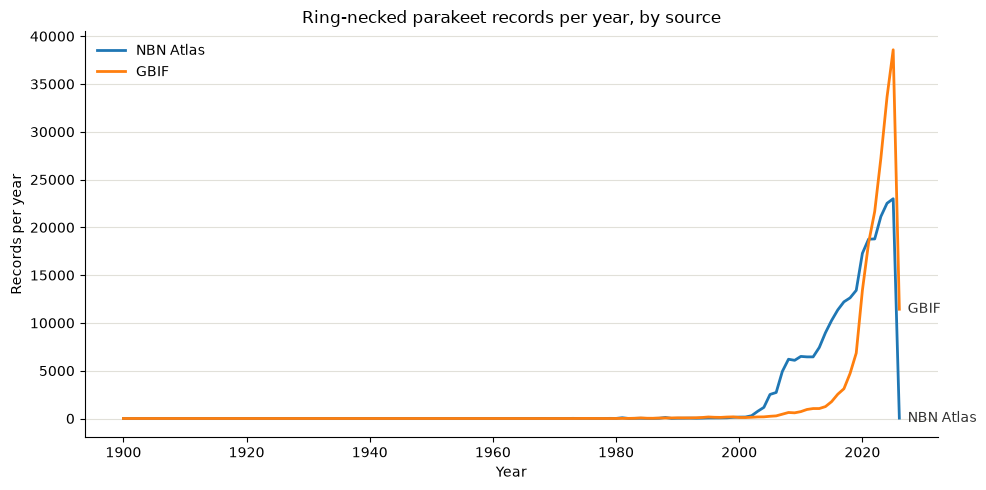

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
for source in per_year.columns:
    ax.plot(per_year.index, per_year[source], linewidth=2, label=source)
    # label each line at its right-hand end
    ax.annotate(source, (per_year.index[-1], per_year[source].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=plot_style.TEXT)

ax.set_xlabel("Year")
ax.set_ylabel("Records per year")
ax.set_title("Ring-necked parakeet records per year, by source")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=plot_style.GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
# ax.set_yscale("log")  # uncomment to see the early decades
plt.tight_layout()

### Presentation version

The same counts in the presentation colours, 1960–2025 (2026 is incomplete). Two figures with the same axes: NBN Atlas only (`records_per_year_nbn.png`), then both sources (`records_per_year_both.png`).

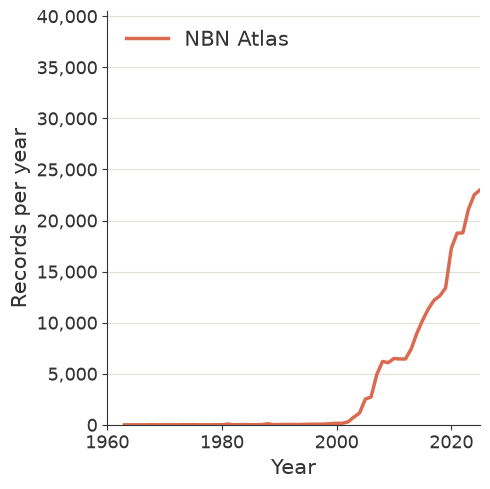

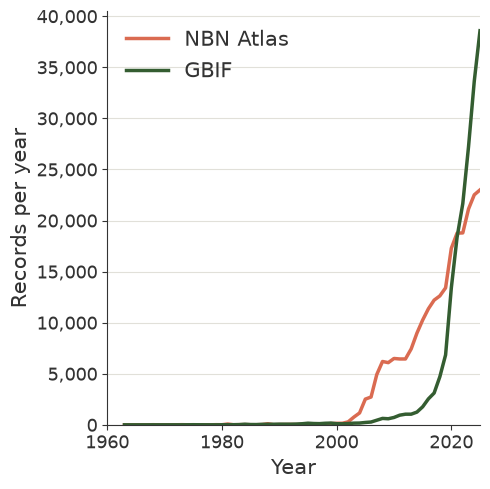

In [8]:
from pathlib import Path

FIGURES = Path("../figures")
SOURCE_COLOURS = {"NBN Atlas": plot_style.SECONDARY, "GBIF": plot_style.PRIMARY_DARK}  # NBN as in 04
TEXT, GRID = plot_style.TEXT, plot_style.GRID
YEARS = (1960, 2025)

shown = per_year.loc[YEARS[0]:YEARS[1]]
y_max = shown.max().max() * 1.05  # same y-axis in both figures


def plot_records(sources, filename):
    fig, ax = plt.subplots(figsize=(5, 5))
    for source in sources:
        ax.plot(shown.index, shown[source], color=SOURCE_COLOURS[source], linewidth=2.5, label=source)
    ax.legend(frameon=False, loc="upper left", fontsize=15, labelcolor=TEXT)
    ax.set_xlim(YEARS[0], YEARS[1])
    ax.set_ylim(0, y_max)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
    ax.set_xlabel("Year", color=TEXT, fontsize=15)
    ax.set_ylabel("Records per year", color=TEXT, fontsize=15)
    #ax.set_title("Ring-necked parakeet records per year", color=TEXT, loc="left", fontsize=17)
    ax.tick_params(colors=TEXT, labelsize=13)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(TEXT)
    plt.tight_layout()
    fig.savefig(FIGURES / filename, dpi=200)
    plt.show()


plot_records(["NBN Atlas"], "records_per_year_nbn.png")
plot_records(["NBN Atlas", "GBIF"], "records_per_year_both.png")

## Overlap between sources

Some NBN data partners also publish to GBIF through the NBN Atlas. For those records, **GBIF `occurrenceID` = NBN `recordID`** (checked on the Suffolk dataset below). NBN's own `occurrenceID` is the data provider's internal code and does not match.

The overlap is small: most GBIF records come from apps that publish only to GBIF (eBird, Birda, iNaturalist), and most NBN records come from "Birds (BTO+partners)", which is not in GBIF.

In [80]:
# For each GBIF dataset: number of records, and the share of them also in NBN
nbn_ids = set(nbn["recordID"])

overlap = (
    gbif.assign(in_nbn=gbif["occurrenceID"].isin(nbn_ids))
        .groupby("datasetKey")
        .agg(n=("in_nbn", "size"), frac_in_nbn=("in_nbn", "mean"))
        .sort_values("n", ascending=False)
)

In [81]:
# The simple GBIF format only has dataset IDs, so look up each dataset's title
# and publisher with the GBIF API (one request per dataset, ~60 in total)
def dataset_info(key):
    d = requests.get(f"https://api.gbif.org/v1/dataset/{key}").json()
    org = requests.get(
        f"https://api.gbif.org/v1/organization/{d['publishingOrganizationKey']}"
    ).json()
    return {"datasetKey": key, "title": d.get("title"), "publisher": org.get("title")}

meta = pd.DataFrame([dataset_info(k) for k in overlap.index])
overlap = overlap.merge(meta, on="datasetKey")

In [82]:
# Datasets with the largest share of records also in NBN
overlap.sort_values("frac_in_nbn", ascending=False).head(25)

,datasetKey,n,frac_in_nbn,title,publisher
30,594e1181-c38a-4f44-b78c-ceab50351cca,15,1.0,National Trust Species Records,National Trust
29,7d17a2b2-8751-41b5-ac9b-48effc1ea236,16,1.0,BRERC species records from all years at full r...,Bristol Regional Environmental Records Centre
20,b6da6358-dd77-41fe-848e-1383f14a9ffb,37,1.0,"House Sparrow Parks Project, London, 2009-2010",Royal Society for the Protection of Birds
49,4f1e2dec-1114-4cb5-8172-bcb1bc39bcab,2,1.0,HNCF BioBlitz and organized survey records fro...,Harrow Nature Conservation Forum
25,b480871a-6c2f-4c35-ab94-6de203c4ff28,25,1.0,Merseyside BioBank Active Naturalists (verified),Merseyside BioBank
26,efde0b80-02d6-4e50-9e6a-4b4329bfeec6,21,1.0,Records of Invasive Non Native Species held on...,Cofnod – North Wales Environmental Information...
27,fd7cda6d-0bdb-44ed-9319-010c286d4633,21,1.0,Leicestershire and Rutland Environmental Recor...,Leicestershire and Rutland Environmental Recor...
28,c3c56ab1-706c-4e7f-85f8-f6f860e203f2,20,1.0,Merseyside BioBank (verified),Merseyside BioBank
48,f14f3ec9-c54a-477d-82c8-f7ba6925534a,2,1.0,UK Roadkill Records,The Road Lab UK
18,1ac5a87d-2256-49b5-af3e-88cf2f651c1d,45,1.0,Cambridgeshire and Peterborough Environmental ...,Cambridgeshire & Peterborough Environmental Re...


In [83]:
# Check of the ID match on one dataset present in both sources (Suffolk, 103 records each).
# GBIF occurrenceID 0a50f974-... = NBN recordID 0a50f974-..., with the same date and coordinates.
# (The first rows differ because GBIF keeps year-only dates as text, which sort first,
#  while NBN leaves them empty, which sorts last.)
suffolk_gbif = gbif[gbif["datasetKey"] == "e707e6da-e143-445d-b41d-529c4a777e8b"].sort_values("eventDate")
suffolk_nbn = nbn[nbn["datasetName"].str.startswith("Suffolk", na=False)].sort_values("eventDate")

print(suffolk_gbif[["occurrenceID", "catalogNumber", "eventDate", "decimalLatitude", "decimalLongitude"]].head())
print(suffolk_nbn[["occurrenceID", "recordID", "eventDate", "decimalLatitude", "decimalLongitude"]].head())

                                occurrenceID catalogNumber   eventDate  \
185297  522e5a29-2ab8-4020-8306-3ea445a7a7f7           NaN        1989   
185290  c72fbb9c-cad8-4409-b76e-7a6a118f6693           NaN        1990   
185333  a5f5dc28-6dce-4840-bbad-7174954b360a           NaN        1990   
185341  814c83a2-2f16-4634-8ae5-8c4a46d2d1c0           NaN     1991-02   
185325  0a50f974-fa8e-4b61-aba5-9dd2993870aa           NaN  1991-03-13   

        decimalLatitude  decimalLongitude  
185297        52.066158          0.960193  
185290        52.202078          0.530135  
185333        52.202078          0.530135  
185341        52.065423          0.989329  
185325        52.405386          1.688735  
            occurrenceID                              recordID  eventDate  \
39062   WA0000050000AZZY  0a50f974-fa8e-4b61-aba5-9dd2993870aa 1991-03-13   
80234   WA0000050000B7JH  2199e2d7-c84d-44cb-96dc-890c92cf3b29 1991-09-03   
233014  WA0000050000B7MH  1f2af47d-4194-4de8-81a4-3b5ff27612

# Merge

Combine both sources into one table, `records`:

- all NBN records, plus
- GBIF records that are not already in NBN (matched on GBIF `occurrenceID` = NBN `recordID`).

For records in both, the NBN version is kept because it has grid references and verification status. Columns are renamed to one shared set, and `source` shows where each record came from.

Not yet handled: the same sighting entered separately in two systems (e.g. eBird and BirdTrack) has different IDs and stays in twice.

In [84]:
# 1. GBIF records not already in NBN
in_nbn = gbif["occurrenceID"].isin(set(nbn["recordID"]))
gbif_only = gbif[~in_nbn]
print(f"GBIF records also in NBN: {in_nbn.sum():,} | GBIF-only: {len(gbif_only):,}")

# 2. Rename to a shared set of columns
#    eventDate: keep only full dates (YYYY-MM-DD), like NBN does. Year-only, year-month
#    and date ranges ("2020-05-01/2020-05-31") become NaT, so no day is made up.
gbif_date = (
    gbif_only["eventDate"]
    .where(~gbif_only["eventDate"].str.contains("/", na=False))
    .str[:10]  # drops times, e.g. "2021-04-03T10:15" -> "2021-04-03"
)
dataset_titles = meta.set_index("datasetKey")["title"]

gbif_std = pd.DataFrame({
    "source": "GBIF",
    "record_id": gbif_only["gbifID"],          # always filled; 36 GBIF records have no occurrenceID
    "occurrenceID": gbif_only["occurrenceID"],
    "dataset": gbif_only["datasetKey"].map(dataset_titles),
    "eventDate": pd.to_datetime(gbif_date, format="%Y-%m-%d", errors="coerce"),
    "year": gbif_only["year"].astype("Int64"),  # Int64 allows missing values in an integer column
    "month": gbif_only["month"].astype("Int64"),
    "decimalLatitude": gbif_only["decimalLatitude"],
    "decimalLongitude": gbif_only["decimalLongitude"],
    "coordinateUncertaintyInMeters": gbif_only["coordinateUncertaintyInMeters"],
    "gridReference": pd.NA,                     # not in the GBIF simple format
    "stateProvince": gbif_only["stateProvince"].str.split(" - ").str[0],  # "England - Kent" -> "England"
    "individualCount": gbif_only["individualCount"],
    "vitality": pd.NA,                          # not in the GBIF simple format
    "countryCode": "GB",                        # the GBIF query was filtered on United Kingdom
    "issue": gbif_only["issue"]
})

nbn_std = pd.DataFrame({
    "source": "NBN",
    "record_id": nbn["recordID"],
    "occurrenceID": nbn["recordID"],            # the ID GBIF uses for NBN records
    "dataset": nbn["datasetName"],
    "eventDate": nbn["eventDate"],
    "year": nbn["year"].astype("Int64"),
    "month": nbn["month"].astype("Int64"),
    "decimalLatitude": nbn["decimalLatitude"],
    "decimalLongitude": nbn["decimalLongitude"],
    "coordinateUncertaintyInMeters": nbn["coordinateUncertaintyInMeters"],
    "gridReference": nbn["gridReference"],
    "stateProvince": nbn["stateProvince"],
    "individualCount": nbn["individualCount"],
    "vitality": nbn["vitality"].str.lower(),    # "Alive" and "alive" -> "alive"
    "countryCode": nbn["countryCode"],
    "issue": pd.NA,                             # GBIF-only field
})

# 3. Stack them and check nothing was lost or doubled
records = pd.concat([nbn_std, gbif_std], ignore_index=True)

assert len(records) == len(nbn) + len(gbif) - in_nbn.sum()
assert records["record_id"].is_unique
records["source"].value_counts()

GBIF records also in NBN: 1,727 | GBIF-only: 190,934


source
NBN     243105
GBIF    190934
Name: count, dtype: int64

In [85]:
# The 36 GBIF records without occurrenceID: which datasets they come from.
# They cannot be matched to NBN by ID, so they always count as GBIF-only.
gbif.loc[gbif["occurrenceID"].isna(), "datasetKey"].map(dataset_titles).value_counts()

datasetKey
NABU|naturgucker                         35
Anymals+plants - Citizen Science Data     1
Name: count, dtype: int64

# Filter

Each filter prints how many records it removes. The reasons are in `decisions.md`.

## Vitality

Only records reported as dead are removed. "Not recorded" and empty carry no information, the same as GBIF records, which have no vitality field.

In [86]:
before = len(records)
records = records[records["vitality"] != "dead"]  # empty vitality is kept (NaN != "dead" is True)
print(f"Removed {before - len(records):,} records (dead)")

Removed 23 records (dead)


## Year

Records without a year can't be used in a yearly analysis. After removing them, the earliest records turn out to be two from 1900, followed by a gap until 1963. Those two are removed as isolated records that say nothing about the spread; everything from 1963 onwards is kept.

In [87]:
# Records without a year, by source (all GBIF: NBN has a year for every record)
no_year = records["year"].isna()
print(no_year.groupby(records["source"]).sum())

# GBIF couldn't interpret the date for these (most are flagged RECORDED_DATE_INVALID)
records.loc[no_year, ["source", "dataset", "eventDate", "issue"]].head(10)

source
GBIF    18
NBN      0
Name: year, dtype: int64


,source,dataset,eventDate,issue
408412,GBIF,Xeno-canto - Bird sounds from around the world,NaT,CONTINENT_DERIVED_FROM_COORDINATES
427510,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427511,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427512,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427513,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427514,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427515,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427516,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427517,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...
427518,GBIF,EBCC Atlas of European Breeding Birds,NaT,INDIVIDUAL_COUNT_INVALID;RECORDED_DATE_INVALID...


In [88]:
before = len(records)
records = records[records["year"].notna()]
print(f"Removed {before - len(records):,} records without a year")

# Range of years left: the minimum (1900) is checked below
print(records["year"].min(), records["year"].max())

Removed 18 records without a year
1900 2026


In [89]:
# The earliest records: two from 1900 (both eBird), then nothing until 1963
early = records[records["year"] < 1965].sort_values("year")
early[["source", "dataset", "year", "month", "eventDate", "decimalLatitude", "decimalLongitude", "issue"]]

,source,dataset,year,month,eventDate,decimalLatitude,decimalLongitude,issue
257331,GBIF,EOD – eBird Observation Dataset,1900,8,1900-08-01,53.847923,-1.470980,GEODETIC_DATUM_ASSUMED_WGS84;CONTINENT_DERIVED...
363821,GBIF,EOD – eBird Observation Dataset,1900,12,1900-12-09,53.347503,-1.453943,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS8...
264109,GBIF,EOD – eBird Observation Dataset,1963,2,1963-02-03,52.152655,-0.483798,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS8...
77452,NBN,Birds (BTO+partners),1964,2,1964-02-17,51.872574,0.141134,<NA>


In [90]:
# Keep everything from 1963 onwards (removes the two 1900 records)
before = len(records)
records = records[records["year"] >= 1963]
print(f"Removed {before - len(records):,} records before 1963")

Removed 2 records before 1963


## Isle of Man

The Isle of Man is not part of the UK, and the GBIF download (filtered on United Kingdom) doesn't include it. Removing its NBN records makes both sources cover the same area.

In [91]:
before = len(records)
records = records[records["countryCode"] != "IM"]  # GBIF records are all "GB"
print(f"Removed {before - len(records):,} Isle of Man records")

Removed 3 Isle of Man records


## GBIF data-quality flags

GBIF flags records where the date or location looked inconsistent. The flags left after the filters above were checked:

- **Date flags** (`RECORDED_DATE_INVALID`, `RECORDED_DATE_MISMATCH`): all have plausible years, mostly from one dataset (LERN Records). Only the year is needed.
- **Location flags** (`COUNTRY_INVALID`): 6 records in central London from the Estonian Ornithological Society, probably a visiting birder. The coordinates are fine; only the country text clashes.

**Result:** all flagged records are kept.

In [92]:
# Number of records with each flag (one record can have several flags, separated by ";")
FLAGS = ["RECORDED_DATE_INVALID", "RECORDED_DATE_MISMATCH",
         "COUNTRY_INVALID", "CONTINENT_COORDINATE_MISMATCH"]

for flag in FLAGS:
    print(flag, records["issue"].str.contains(flag, na=False).sum())

RECORDED_DATE_INVALID 16
RECORDED_DATE_MISMATCH 2
COUNTRY_INVALID 6
CONTINENT_COORDINATE_MISMATCH 0


In [93]:
# Date-flagged records: are the years plausible?
date_flag = records["issue"].str.contains("RECORDED_DATE", na=False)
records.loc[date_flag, ["dataset", "year", "month", "eventDate", "issue"]].sort_values("year")

,dataset,year,month,eventDate,issue
432493,LERN Records,1981,9,1981-09-06,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
432597,LERN Records,1987,9,1987-09-07,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
408714,Montgomeryshire Wildlife Trust records held by...,1998,<NA>,NaT,RECORDED_DATE_MISMATCH;CONTINENT_DERIVED_FROM_...
433908,INNS records held by BIS in Powys and Brecon B...,1998,<NA>,NaT,RECORDED_DATE_MISMATCH;CONTINENT_DERIVED_FROM_...
432642,LERN Records,1999,11,1999-11-01,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
433909,INNS records held by BIS in Powys and Brecon B...,2006,1,2006-01-05,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
432562,LERN Records,2018,4,2018-04-12,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
432614,LERN Records,2018,10,2018-10-12,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
432626,LERN Records,2018,1,2018-01-08,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...
432640,LERN Records,2018,11,2018-11-01,RECORDED_DATE_INVALID;CONTINENT_DERIVED_FROM_C...


In [94]:
# Location-flagged records: are the points in the UK?
loc_flag = records["issue"].str.contains("COUNTRY_INVALID|CONTINENT_COORDINATE_MISMATCH", na=False)
flagged = records[loc_flag]

# Rough UK bounding box (also includes a strip of northern France and part of Ireland)
in_uk_box = flagged["decimalLatitude"].between(49.8, 61.0) & flagged["decimalLongitude"].between(-8.7, 1.8)
print(f"{in_uk_box.sum()} of {len(flagged)} flagged points inside the UK box")

flagged[["dataset", "decimalLatitude", "decimalLongitude", "stateProvince", "issue"]]

6 of 6 flagged points inside the UK box


,dataset,decimalLatitude,decimalLongitude,stateProvince,issue
408707,Estonian Ornithological Society (BirdLife Esto...,51.481697,-0.094488,NaN,COORDINATE_ROUNDED;COUNTRY_DERIVED_FROM_COORDI...
408708,Estonian Ornithological Society (BirdLife Esto...,51.492473,-0.089480,NaN,COORDINATE_ROUNDED;COUNTRY_DERIVED_FROM_COORDI...
408709,Estonian Ornithological Society (BirdLife Esto...,51.491934,-0.086251,NaN,COORDINATE_ROUNDED;COUNTRY_DERIVED_FROM_COORDI...
408710,Estonian Ornithological Society (BirdLife Esto...,51.504620,-0.158947,NaN,COORDINATE_ROUNDED;COUNTRY_DERIVED_FROM_COORDI...
408711,Estonian Ornithological Society (BirdLife Esto...,51.503602,-0.154570,NaN,COUNTRY_DERIVED_FROM_COORDINATES;COUNTRY_INVAL...
408712,Estonian Ornithological Society (BirdLife Esto...,51.492358,-0.087595,NaN,COORDINATE_ROUNDED;COUNTRY_DERIVED_FROM_COORDI...


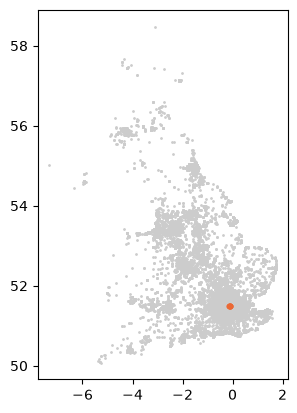

In [95]:
# All records (grey) with the location-flagged ones (terracotta): the flagged points are in central London
plt.scatter(records["decimalLongitude"], records["decimalLatitude"], s=1, color=plot_style.GRID)
plt.scatter(flagged["decimalLongitude"], flagged["decimalLatitude"], s=10, color=plot_style.SECONDARY)
plt.gca().set_aspect(1.6)  # rough correction so the UK isn't squashed

# Result

After merging and filtering, 433,993 records remain. `src/build_records.py` repeats the merge and filters and saves this table to `data/processed/records.parquet`.

Spatial unit and coordinate uncertainty are settled in `02_spatial-unit` (10 km squares). Still open: the same sighting entered in two systems (e.g. eBird and BirdTrack); see `notes.md`.